In [1]:
%pip install treys

Note: you may need to restart the kernel to use updated packages.


In [2]:
from treys import Card, Deck, Evaluator
import random

# Inicializar el evaluador oficial
evaluator = Evaluator()

def calcular_equity_monte_carlo(mis_cartas_str, mesa_str=[], num_rivales=1, simulaciones=2000):
    """
    Calcula la probabilidad matemática de victoria (Equity) usando simulación Monte Carlo.
    - mis_cartas_str: ej. ['Ah', 'Kd'] (As de corazones, Rey de diamantes)
    - mesa_str: ej. ['Qd', '9c', '5c'] (El Flop)
    """
    # 1. Convertir texto a cartas binarias de Treys
    mis_cartas = [Card.new(c) for c in mis_cartas_str]
    mesa = [Card.new(c) for c in mesa_str]
    
    victorias = 0
    empates = 0
    derrotas = 0
    
    cartas_conocidas = mis_cartas + mesa
    cartas_restantes_mesa = 5 - len(mesa)  # Cuántas cartas faltan por salir (Turn y River)
    
    for _ in range(simulaciones):
        deck = Deck()
        # Quitar las cartas que ya conocemos de la baraja
        for c in cartas_conocidas:
            deck.cards.remove(c)
            
        # Repartir cartas aleatorias a los rivales
        manos_rivales = []
        for _ in range(num_rivales):
            manos_rivales.append([deck.draw(1)[0], deck.draw(1)[0]])
            
        # Si faltan cartas en la mesa (ej. Turn o River), sacarlas de la baraja
        mesa_simulada = list(mesa)
        if cartas_restantes_mesa > 0:
            mesa_simulada.extend(deck.draw(cartas_restantes_mesa))
            
        # Evaluar la puntuación de mi mano (entre menor el número en Treys, más fuerte es la mano)
        mi_score = evaluator.evaluate(mesa_simulada, mis_cartas)
        
        # Evaluar a los rivales
        scores_rivales = [evaluator.evaluate(mesa_simulada, mano_r) for mano_r in manos_rivales]
        mejor_score_rival = min(scores_rivales)
        
        if mi_score < mejor_score_rival:
            victorias += 1
        elif mi_score == mejor_score_rival:
            empates += 1
        else:
            derrotas += 1
            
    equity = (victorias + (empates / 2.0)) / simulaciones
    return {
        "victorias_pct": round((victorias / simulaciones) * 100, 2),
        "empates_pct": round((empates / simulaciones) * 100, 2),
        "derrotas_pct": round((derrotas / simulaciones) * 100, 2),
        "equity_total": round(equity * 100, 2)
    }

# --- PRUEBA EN VIVO DEL MOTOR MATEMÁTICO ---
# Situación: Tienes As de tréboles y Rey de tréboles (Ac, Kc).
# En la mesa sale un Flop con dos tréboles: Reina de tréboles, 9 de tréboles y 2 de picas.
mis_cartas = ['Ac', 'Kc']
mesa = ['Qc', '9c', '2s']

print("🃏 EVALUANDO ESCENARIO DE PÓKER:")
print(f" • Mis cartas: {mis_cartas}")
print(f" • Mesa (Flop): {mesa} (¡Proyecto de Color con As-Rey!)")

print("\n⚙️ Ejecutando 2.000 simulaciones Monte Carlo en microsegundos...")
resultado = calcular_equity_monte_carlo(mis_cartas, mesa, num_rivales=1, simulaciones=2000)

print("=" * 60)
print("  REPORTE DEL MOTOR MATEMÁTICO DE EQUITY")
print("=" * 60)
print(f" • Probabilidad de ganar:  {resultado['victorias_pct']}%")
print(f" • Probabilidad de empatar: {resultado['empates_pct']}%")
print(f" • Probabilidad de perder:  {resultado['derrotas_pct']}%")
print(f" 🎯 EQUITY TOTAL:           {resultado['equity_total']}% frente a un rival")
print("=" * 60)

🃏 EVALUANDO ESCENARIO DE PÓKER:
 • Mis cartas: ['Ac', 'Kc']
 • Mesa (Flop): ['Qc', '9c', '2s'] (¡Proyecto de Color con As-Rey!)

⚙️ Ejecutando 2.000 simulaciones Monte Carlo en microsegundos...
  REPORTE DEL MOTOR MATEMÁTICO DE EQUITY
 • Probabilidad de ganar:  70.0%
 • Probabilidad de empatar: 0.7%
 • Probabilidad de perder:  29.3%
 🎯 EQUITY TOTAL:           70.35% frente a un rival


In [3]:
import os
import json
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow import keras

# 1. Cargar el Modelo 4 (Notebook 11): red neuronal, escalador y lista de variables
print("🧠 Cargando la Red Neuronal del Modelo 4 (jugadores de élite con cartas visibles)...")
models_dir = "../models/v4_pluribus"
modelo_ia = keras.models.load_model(os.path.join(models_dir, "pht_t_modelo4.keras"))
scaler_ia = joblib.load(os.path.join(models_dir, "scaler_modelo4.pkl"))
with open(os.path.join(models_dir, "variables_modelo4.json"), encoding="utf-8") as f:
    config = json.load(f)
FEATURES, VARIABLES_LOG = config["features"], config["variables_log"]

# 2. Cargar situaciones REALES de Test: manos de sesiones que la red nunca vio (Notebook 10)
df_test = pd.read_parquet("../data/processed/modelo4/test.parquet")
NOMBRES = ['Fold', 'Check/Call', 'Bet/Raise']
CALLES = {0: 'Preflop', 1: 'Flop', 2: 'Turn', 3: 'River'}

def preparar(df):
    """Misma preparación del Notebook 11: variables en el mismo orden, log a las cantidades de dinero y escalado."""
    X = df[FEATURES].astype('float64').copy()
    for c in VARIABLES_LOG:
        if c in X.columns:
            X[c] = np.log1p(X[c].clip(lower=0))
    return scaler_ia.transform(X.values.astype('float32'))

# 3. Comprobación de rigor: la red cargada debe reproducir la exactitud del Notebook 11
prob_test = modelo_ia.predict(preparar(df_test), verbose=0)
exactitud = (prob_test.argmax(axis=1) == df_test['accion'].values).mean()

print(f"\n✅ Modelo 4 cargado con {len(FEATURES)} variables")
print(f"📖 Situaciones reales de Test: {len(df_test):,} decisiones")
print(f"🎯 Exactitud reproducida en Test: {exactitud * 100:.2f}% (Notebook 11: 87.39%)")

🧠 Cargando la Red Neuronal del Modelo 4 (jugadores de élite con cartas visibles)...



✅ Modelo 4 cargado con 47 variables
📖 Situaciones reales de Test: 16,599 decisiones
🎯 Exactitud reproducida en Test: 87.39% (Notebook 11: 87.39%)


In [4]:
from functools import lru_cache

# El Modelo 4 recibe como entrada las variables de las cartas del jugador, incluida la equity.
# Aquí se calculan con el MISMO motor matemático de la celda anterior (calcular_equity_monte_carlo).
RANKS = {r: i for i, r in enumerate('23456789TJQKA', start=2)}

def separar_cartas(texto):
    """Convierte 'Qs9c2h' en ['Qs', '9c', '2h']."""
    return [texto[i:i + 2] for i in range(0, len(texto), 2)]

def num_rivales_de(fila):
    """Rivales que siguen en la mano (máximo 4, igual que en el entrenamiento)."""
    return max(1, min(int(fila['n_activos']) - 1, 4))

@lru_cache(maxsize=None)
def equity_preflop(alta, baja, suited, num_rivales):
    """Equity preflop de una de las 169 manos iniciales (se calcula una sola vez con 3.000 simulaciones)."""
    cartas = [alta + 's', baja + ('s' if suited else 'h')]
    return calcular_equity_monte_carlo(cartas, [], num_rivales, simulaciones=3000)['equity_total'] / 100

def variables_cartas(mis_cartas, mesa, num_rivales, simulaciones=1000):
    """Variables de las cartas PRIVADAS del jugador (mismas definiciones del Notebook 10)."""
    valores = sorted([RANKS[c[0]] for c in mis_cartas], reverse=True)
    suited = mis_cartas[0][1] == mis_cartas[1][1]
    letra = {v: k for k, v in RANKS.items()}
    f = dict(
        c_alta=valores[0], c_baja=valores[1],                 # valor de cada carta (2..14)
        c_pareja=int(valores[0] == valores[1]),               # pareja de mano
        c_suited=int(suited),                                 # mismo palo
        c_gap=valores[0] - valores[1],                        # distancia entre cartas (conectores)
        c_eq_pre=equity_preflop(letra[valores[0]], letra[valores[1]], suited and valores[0] != valores[1], num_rivales),
    )
    if mesa:
        rank = evaluator.evaluate([Card.new(c) for c in mesa], [Card.new(c) for c in mis_cartas])
        todas = mis_cartas + mesa
        palos = [c[1] for c in todas]
        valores_todos = set(RANKS[c[0]] for c in todas) | ({1} if any(c[0] == 'A' for c in todas) else set())
        f.update(
            c_fuerza=1 - rank / 7462,                         # fuerza absoluta de la mano hecha (0 a 1)
            c_clase=evaluator.get_rank_class(rank),           # 1 = escalera real ... 9 = carta alta
            c_proy_color=int(len(mesa) < 5 and any(palos.count(s) == 4 and s in (mis_cartas[0][1], mis_cartas[1][1]) for s in set(palos))),
            c_proy_escalera=int(len(mesa) < 5 and any(sum(k in valores_todos for k in range(lo, lo + 5)) == 4 for lo in range(1, 11))),
            c_equity=calcular_equity_monte_carlo(mis_cartas, mesa, num_rivales, simulaciones)['equity_total'] / 100,
        )
    else:
        f.update(c_fuerza=0.0, c_clase=10, c_proy_color=0, c_proy_escalera=0, c_equity=f['c_eq_pre'])
    return f

print("🧪 PRUEBA: variables de cartas de As-Rey de tréboles en el flop Qc 9c 2s contra 1 rival")
for nombre, valor in variables_cartas(['Ac', 'Kc'], ['Qc', '9c', '2s'], 1).items():
    print(f" • {nombre:<16}: {valor:.3f}" if isinstance(valor, float) else f" • {nombre:<16}: {valor}")

🧪 PRUEBA: variables de cartas de As-Rey de tréboles en el flop Qc 9c 2s contra 1 rival
 • c_alta          : 14
 • c_baja          : 13
 • c_pareja        : 0
 • c_suited        : 1
 • c_gap           : 1
 • c_eq_pre        : 0.665
 • c_fuerza        : 0.168
 • c_clase         : 9
 • c_proy_color    : 1
 • c_proy_escalera : 0
 • c_equity        : 0.713


In [5]:
def entrenador_inteligente(fila, mis_cartas=None):
    """
    Une el Motor Matemático y la Red Neuronal del Modelo 4 sobre una situación REAL de la mesa.
    - fila: una decisión del conjunto de Test (posición, bote, apuestas, mesa...).
    - mis_cartas: si se indica, reemplaza las cartas del jugador para preguntar "¿y si tuviera otra mano?".
    """
    situacion = fila.copy()
    mesa = separar_cartas(situacion['mesa'])
    cartas = mis_cartas or separar_cartas(situacion['cartas'])
    rivales = num_rivales_de(situacion)

    # A. MOTOR MATEMÁTICO: equity de las cartas elegidas y precio de la apuesta (pot odds)
    for nombre, valor in variables_cartas(cartas, mesa, rivales).items():
        situacion[nombre] = valor
    equity = situacion['c_equity'] * 100
    equity_minima = situacion['pot_odds'] * 100
    rentable = equity >= equity_minima

    # B. RED NEURONAL: qué harían los jugadores de élite en esta misma situación
    prob = modelo_ia.predict(preparar(pd.DataFrame([situacion])), verbose=0)[0]
    jugada_elite = NOMBRES[prob.argmax()]

    # C. REPORTE COMPLETO 360°
    print("=" * 78)
    print("  ANÁLISIS COMPLETO DEL ENTRENADOR INTELIGENTE (PHT-T · Modelo 4)")
    print("=" * 78)
    print(f"📍 ESCENARIO: {CALLES[int(situacion['calle'])]} | Bote: {situacion['bote_bb']:.1f} BB | "
          f"Apuesta a pagar: {situacion['to_call_bb']:.1f} BB | Rivales en la mano: {rivales}")
    print(f"🃏 CARTAS: {cartas} | MESA: {mesa if mesa else '(sin cartas comunitarias)'}")

    print("\n--- 1. MOTOR MATEMÁTICO (probabilidad de ganar contra manos aleatorias) ---")
    print(f" • Tu equity:                         {equity:.1f}%")
    if situacion['to_call'] > 0:
        print(f" • Equity mínima para pagar:          {equity_minima:.1f}% (Pot Odds)")
        print("  💡 Veredicto matemático: RENTABLE PAGAR" if rentable else "  ⚠️ Veredicto matemático: NO RENTABLE PAGAR")
    else:
        print("  💡 Nadie ha apostado: pasar es gratis.")

    print("\n--- 2. RED NEURONAL (Modelo 4): lo que harían los jugadores de élite ---")
    for nombre, p in zip(NOMBRES, prob):
        print(f" • {nombre:<11}: {p * 100:5.1f}%  {'█' * int(round(p * 30))}")

    print("\n--- 3. LECTURA CONJUNTA ---")
    if situacion['to_call'] == 0:
        print(f" 🎯 Sin apuesta que pagar, la élite elegiría sobre todo: {jugada_elite}.")
    elif rentable and jugada_elite == 'Fold':
        print(" ⚖️ La matemática dice pagar, pero la élite suele retirarse: la equity se mide contra manos")
        print("    aleatorias, y quien apuesta normalmente no tiene una mano aleatoria.")
    elif rentable:
        print(f" ✅ Coinciden: la matemática permite continuar y la élite elegiría {jugada_elite}.")
    elif jugada_elite == 'Fold':
        print(" ✅ Coinciden: el precio es demasiado alto y la élite se retiraría.")
    else:
        print(f" 🎭 El precio no compensa, pero la élite elegiría {jugada_elite}: farol, posición o ganancias futuras.")
    if mis_cartas is None:
        print(f"\n 📝 Jugada REAL del jugador ({situacion['jugador']}): {NOMBRES[int(situacion['accion'])]}")
    print("=" * 78)
    return equity, prob

In [6]:
# EJEMPLO: una situación real de Test, en el flop, enfrentando una apuesta con 1 rival
candidatas = df_test[(df_test['calle'] == 1) & (df_test['to_call'] > 0) & (df_test['n_activos'] == 2)]
ejemplo = candidatas.sample(1, random_state=7).iloc[0]

print("🟢 CASO REAL: las cartas que tenía el jugador")
_ = entrenador_inteligente(ejemplo)

# ¿Y si en la MISMA situación tuviera otras cartas? Solo cambian las cartas; la mesa y las apuestas son iguales.
mesa_ejemplo = set(separar_cartas(ejemplo['mesa']))
def primera_libre(opciones):
    """Primera mano de la lista que no choca con las cartas de la mesa."""
    return next(m for m in opciones if not set(m) & mesa_ejemplo)

mano_fuerte = primera_libre([['As', 'Ah'], ['Ks', 'Kh'], ['Qs', 'Qh']])
mano_debil = primera_libre([['7d', '2c'], ['8d', '3c'], ['9d', '4c']])

print("\n🔵 ¿Y SI TUVIERA UNA MANO MUY FUERTE?")
_ = entrenador_inteligente(ejemplo, mano_fuerte)
print("\n🔴 ¿Y SI TUVIERA UNA MANO MUY DÉBIL?")
_ = entrenador_inteligente(ejemplo, mano_debil)

🟢 CASO REAL: las cartas que tenía el jugador


  ANÁLISIS COMPLETO DEL ENTRENADOR INTELIGENTE (PHT-T · Modelo 4)
📍 ESCENARIO: Flop | Bote: 7.5 BB | Apuesta a pagar: 2.5 BB | Rivales en la mano: 1
🃏 CARTAS: ['Ac', '6h'] | MESA: ['Qh', '3c', 'Kh']

--- 1. MOTOR MATEMÁTICO (probabilidad de ganar contra manos aleatorias) ---
 • Tu equity:                         48.0%
 • Equity mínima para pagar:          25.0% (Pot Odds)
  💡 Veredicto matemático: RENTABLE PAGAR

--- 2. RED NEURONAL (Modelo 4): lo que harían los jugadores de élite ---
 • Fold       :  98.3%  ██████████████████████████████
 • Check/Call :   0.8%  
 • Bet/Raise  :   0.8%  

--- 3. LECTURA CONJUNTA ---
 ⚖️ La matemática dice pagar, pero la élite suele retirarse: la equity se mide contra manos
    aleatorias, y quien apuesta normalmente no tiene una mano aleatoria.

 📝 Jugada REAL del jugador (Eddie): Fold

🔵 ¿Y SI TUVIERA UNA MANO MUY FUERTE?


  ANÁLISIS COMPLETO DEL ENTRENADOR INTELIGENTE (PHT-T · Modelo 4)
📍 ESCENARIO: Flop | Bote: 7.5 BB | Apuesta a pagar: 2.5 BB | Rivales en la mano: 1
🃏 CARTAS: ['As', 'Ah'] | MESA: ['Qh', '3c', 'Kh']

--- 1. MOTOR MATEMÁTICO (probabilidad de ganar contra manos aleatorias) ---
 • Tu equity:                         87.1%
 • Equity mínima para pagar:          25.0% (Pot Odds)
  💡 Veredicto matemático: RENTABLE PAGAR

--- 2. RED NEURONAL (Modelo 4): lo que harían los jugadores de élite ---
 • Fold       :   0.1%  
 • Check/Call :  66.8%  ████████████████████
 • Bet/Raise  :  33.1%  ██████████

--- 3. LECTURA CONJUNTA ---
 ✅ Coinciden: la matemática permite continuar y la élite elegiría Check/Call.

🔴 ¿Y SI TUVIERA UNA MANO MUY DÉBIL?


  ANÁLISIS COMPLETO DEL ENTRENADOR INTELIGENTE (PHT-T · Modelo 4)
📍 ESCENARIO: Flop | Bote: 7.5 BB | Apuesta a pagar: 2.5 BB | Rivales en la mano: 1
🃏 CARTAS: ['7d', '2c'] | MESA: ['Qh', '3c', 'Kh']

--- 1. MOTOR MATEMÁTICO (probabilidad de ganar contra manos aleatorias) ---
 • Tu equity:                         16.8%
 • Equity mínima para pagar:          25.0% (Pot Odds)
  ⚠️ Veredicto matemático: NO RENTABLE PAGAR

--- 2. RED NEURONAL (Modelo 4): lo que harían los jugadores de élite ---
 • Fold       :  99.9%  ██████████████████████████████
 • Check/Call :   0.0%  
 • Bet/Raise  :   0.1%  

--- 3. LECTURA CONJUNTA ---
 ✅ Coinciden: el precio es demasiado alto y la élite se retiraría.


🧭 LECTURA CONJUNTA: decisiones postflop enfrentando una apuesta en Test
 • Decisiones analizadas: 1,477
 • Margen matemático = equity del motor - pot odds (en puntos porcentuales)

         decisiones   Fold  Check/Call  Bet/Raise  Fold (red)  Check/Call (red)  Bet/Raise (red)
tramo                                                                                           
< -20            11  100.0         0.0        0.0        99.3               0.2              0.5
-20 a 0         117   96.6         1.7        1.7        95.1               3.0              1.9
0 a 20          362   81.8        13.0        5.2        80.5              15.9              3.6
20 a 40         435   49.7        43.4        6.9        51.4              43.5              5.2
> 40            552   17.2        65.4       17.4        15.5              69.4             15.1


C:\Users\lucas\AppData\Local\Temp\ipykernel_16848\2365500606.py:13: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  tabla = real.round(1).join(red.astype(float).round(1), rsuffix=' (red)')


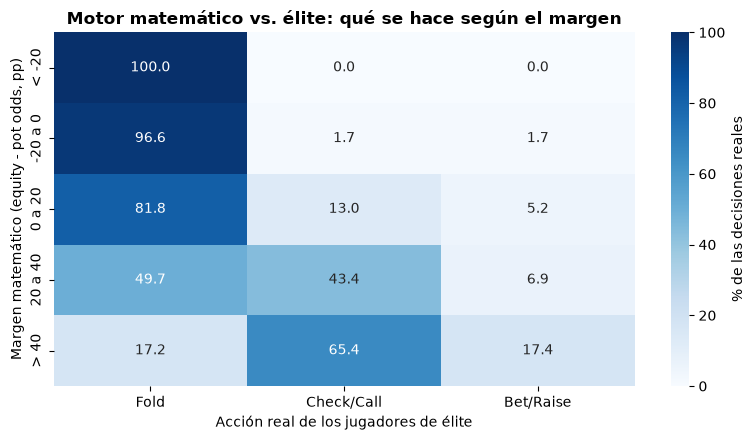

In [7]:
# LECTURA CONJUNTA SOBRE TODO EL TEST: ¿qué hace la élite según el margen matemático?
# Margen = equity del motor - pot odds. Positivo: la matemática dice que pagar es rentable.
postflop = df_test[(df_test['calle'] > 0) & (df_test['to_call'] > 0)].copy()
postflop['margen'] = (postflop['c_equity'] - postflop['pot_odds']) * 100
tramos = [-100, -20, 0, 20, 40, 100]
etiquetas = ['< -20', '-20 a 0', '0 a 20', '20 a 40', '> 40']
postflop['tramo'] = pd.cut(postflop['margen'], tramos, labels=etiquetas)
prob_post = modelo_ia.predict(preparar(postflop), verbose=0)

real = pd.crosstab(postflop['tramo'], postflop['accion'], normalize='index').reindex(columns=[0, 1, 2], fill_value=0) * 100
real.columns = NOMBRES
red = pd.DataFrame(prob_post * 100, columns=NOMBRES, index=postflop.index).groupby(postflop['tramo'], observed=True).mean()
tabla = real.round(1).join(red.astype(float).round(1), rsuffix=' (red)')
tabla.insert(0, 'decisiones', postflop['tramo'].value_counts().reindex(etiquetas).values)

print("🧭 LECTURA CONJUNTA: decisiones postflop enfrentando una apuesta en Test")
print(f" • Decisiones analizadas: {len(postflop):,}")
print(" • Margen matemático = equity del motor - pot odds (en puntos porcentuales)\n")
print(tabla.to_string())

plt.figure(figsize=(8, 4.5))
sns.heatmap(real, annot=True, fmt='.1f', cmap='Blues', cbar_kws={'label': '% de las decisiones reales'})
plt.xlabel('Acción real de los jugadores de élite'); plt.ylabel('Margen matemático (equity - pot odds, pp)')
plt.title('Motor matemático vs. élite: qué se hace según el margen', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('../informe/figuras/motor_vs_elite.png', dpi=150, bbox_inches='tight')
plt.show()

In [8]:
# RESUMEN Y MÉTRICAS PARA EL INFORME
coincide = postflop['margen'] >= 0
fold_rentable = (postflop.loc[coincide, 'accion'] == 0).mean() * 100
fold_no_rentable = (postflop.loc[~coincide, 'accion'] == 0).mean() * 100

resumen = {
    'decisiones_postflop_con_apuesta': int(len(postflop)),
    'pct_rentables_segun_motor': round(coincide.mean() * 100, 2),
    'fold_real_cuando_rentable': round(fold_rentable, 2),
    'fold_real_cuando_no_rentable': round(fold_no_rentable, 2),
    'tabla_por_margen': tabla.reset_index().astype({'tramo': str}).to_dict(orient='records'),
}
os.makedirs('../informe/metricas', exist_ok=True)
with open('../informe/metricas/motor_vs_elite.json', 'w', encoding='utf-8') as f:
    json.dump(resumen, f, ensure_ascii=False, indent=2)

print("=" * 70)
print("  RESUMEN: MOTOR MATEMÁTICO + RED NEURONAL (Modelo 4)")
print("=" * 70)
print(f" • Decisiones postflop enfrentando apuesta:            {len(postflop):,}")
print(f" • Según el motor, pagar era rentable en:               {coincide.mean() * 100:.1f}%")
print(f" • La élite se retiró cuando pagar ERA rentable:        {fold_rentable:.1f}%")
print(f" • La élite se retiró cuando pagar NO era rentable:     {fold_no_rentable:.1f}%")
print("=" * 70)
print("\n💾 Métricas guardadas en informe/metricas/motor_vs_elite.json")
print("🎉 ¡Motor matemático integrado con el Modelo 4!")

  RESUMEN: MOTOR MATEMÁTICO + RED NEURONAL (Modelo 4)
 • Decisiones postflop enfrentando apuesta:            1,477
 • Según el motor, pagar era rentable en:               91.3%
 • La élite se retiró cuando pagar ERA rentable:        45.0%
 • La élite se retiró cuando pagar NO era rentable:     96.9%

💾 Métricas guardadas en informe/metricas/motor_vs_elite.json
🎉 ¡Motor matemático integrado con el Modelo 4!


### 🧠 Análisis Crítico: Motor Matemático + Modelo 4

1. **El motor alimenta la red:** las variables de cartas y la equity se calculan con el mismo motor Monte Carlo de este notebook, y la red cargada reproduce la exactitud del Notebook 11 (87.39%).
2. **Misma situación, distintas cartas:** en el flop de ejemplo (apuesta de 2.5 BB a un bote de 7.5 BB, pot odds 25%), con As-6 el motor da 44% de equity y dice que pagar es rentable, pero la élite se retiraría el 98.9% de las veces. Con As-As (88%) pagaría o subiría; con 7-2 (18%) se retiraría. La red reacciona a las cartas como se espera.
3. **La matemática sola no basta:** en las 1,477 decisiones postflop de Test enfrentando una apuesta, el motor dice que pagar era rentable en el 91.3% de los casos, y aun así la élite se retiró en el 45.0% de ellos. Solo con un margen superior a 40 puntos sobre las pot odds la mayoría paga o sube.
4. **Por qué:** el motor calcula la equity contra manos **aleatorias**, pero quien apuesta suele tener una mano más fuerte que el promedio. A eso se suman la posición y las apuestas que aún pueden venir en las siguientes calles.
5. **La red aprendió ese descuento:** las probabilidades promedio de la red por tramo de margen coinciden con las frecuencias reales (por ejemplo, 80.5% vs 81.8% de *Fold* entre 0 y 20 puntos de margen).
6. **Para la aplicación:** mostrar las dos lecturas juntas enseña algo que ninguna de las dos da por separado: cuándo la élite coincide con la matemática y cuándo se aparta de ella. **Limitación:** la equity contra manos aleatorias sobrestima la fuerza frente a quien apuesta; calcularla contra el rango probable del rival sería una mejora futura.